# 02 -- Size extensivity: (H2)_N chains

**Status: full production sweep, superseding the pilot's single N=8 point.** The pilot's frozen record (`data/results/02_size_extensivity/h2_chain_pilot.json`,
read-only) is untouched; this run writes to a separate file
(`data/results/02_size_extensivity/production_sweep.json`) with its own manifest hash, per
the "preserve pilot records" directive.

**Methodology note:** an initial pilot found that `free_coo` at a
small `las_top_k` can fail *catastrophically* (not just approximately) on this
weakly-coupled system -- confirmed decisively below to originate in top-K union
*construction* itself (`free_coo_e_before`, evaluated immediately after truncation and
before any orbital optimization, already carries the full error; orbital optimization
neither causes nor meaningfully worsens/fixes it). Consequences for this notebook:

- **Parent energy is the primary extensivity result** at every `N`.
- Generalized/union/free-COO are only attempted where the **exact, untruncated** LAS
  product is computationally tractable (`N <= 8`, product size `<= 65536`) -- never with a
  fixed `las_top_k` compared across different `N` as though it meant the same fraction of
  the product space at each `N`.
- At `N=16`, the exact union (`4**16 ~= 4.3e9` terms) is far beyond the "few hundred
  thousand" tractability limit documented in the release README -- recovery/union/free-COO
  are **not attempted at all** at this `N`; only the parent energy is reported.
- One concise, clearly-labeled ablation (not part of the main curve) demonstrates the
  catastrophic-truncation failure mode at `N=8`.
- `N=32` is parent-only, exactly as originally planned.

System: N well-separated H2 units on a line (`r_HH=1.4` bohr bond, `6.0` bohr gap between
units), Boys-localized and centroid-sorted (see the pilot notebook/PROVENANCE discussion for
why canonical HF MOs are wrong here). Each fragment: 2 orbitals, `(1,1)e`, `spin_sub=1`.


In [ ]:
import sys
from pathlib import Path

RELEASE_ROOT = Path.cwd().parent
if not (RELEASE_ROOT / "frasci" / "__init__.py").exists():
    RELEASE_ROOT = Path.cwd()
assert (RELEASE_ROOT / "frasci" / "__init__.py").exists(), (
    f"release root not found relative to {Path.cwd()}")

assert "frasci" not in sys.modules, (
    "frasci was already imported before the release-first bootstrap ran")

sys.path.insert(0, str(RELEASE_ROOT))

import frasci
frasci_path = Path(frasci.__file__).resolve()
assert frasci_path.is_relative_to(RELEASE_ROOT.resolve()), (
    f"Using frasci from {frasci_path}, NOT from the release root {RELEASE_ROOT} -- "
    "the dev-tree package shadowed the release one")
print(f"Using FRASCI from: {frasci_path}")
print(f"frasci.__version__: {getattr(frasci, '__version__', 'unknown')}")

import frasci.parent as parent_pkg
import frasci.recovery as recovery_pkg
print("parent pkg importable:", bool(parent_pkg))
print("recovery pkg importable:", bool(recovery_pkg))


In [ ]:
import time, shutil, json, hashlib
from pathlib import Path
import numpy as np
from pyscf import gto, scf, lo
from pyscf.tools import fcidump

from frasci import FCIDUMPInput
from frasci.parent import ParentConfig, solve as solve_parent
from frasci.recovery import RecoveryConfig, solve as solve_recovery

RUN_ROOT = Path("/tmp/frasci_nb02_production_runs")   # local scratch, never committed
shutil.rmtree(RUN_ROOT, ignore_errors=True)
RUN_ROOT.mkdir(parents=True)

RESULTS_DIR = Path("data/results/02_size_extensivity")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

R_HH = 1.4   # bond length, bohr
SEP = 6.0    # gap between adjacent H2 units, bohr

# The exact-union tractability ceiling this release's own README documents ("a few hundred
# thousand determinants") -- 4**N for N=8 is 65536, comfortably inside it; 4**16 is not.
EXACT_UNION_CEILING = 100_000


def build_h2_chain_fcidump(n: int, path: Path):
    atoms = []
    cursor = 0.0
    for i in range(n):
        atoms.append(("H", (cursor, 0.0, 0.0)))
        atoms.append(("H", (cursor + R_HH, 0.0, 0.0)))
        cursor += R_HH + SEP
    mol = gto.M(atom=atoms, basis="sto-3g", unit="Bohr", verbose=0)
    mf = scf.RHF(mol)
    mf.verbose = 0
    mf.kernel()
    if not mf.converged:
        raise RuntimeError(f"H2 chain (N={n}) RHF did not converge")
    localized = lo.Boys(mol, mf.mo_coeff).kernel()
    centers = np.einsum("pi,pq,qi->i", localized, mol.intor("int1e_r")[0], localized)
    ordered = localized[:, np.argsort(centers)]
    fcidump.from_mo(mol, str(path), ordered)


## Ablation: top-K truncation can fail catastrophically (N=8, not part of the main curve)

In [ ]:
def run_parent(n, phase1_dets=200):
    path = RUN_ROOT / f"h2n_{n}_ablation.fcidump"
    build_h2_chain_fcidump(n, path)
    orbital_lists = [[2 * i, 2 * i + 1] for i in range(n)]
    nelec_per_frag = [(1, 1)] * n
    spin_sub = [1] * n
    config = ParentConfig(threshold=1e-6, max_cycle_macro=30, orbopt=True, orbopt_cycles=5,
                           phase0_dets=16, phase1_dets=phase1_dets, discovery_num_runs=8,
                           refine_num_runs=1, n_cpu_workers=0, rng_seed=0)
    save_dir = RUN_ROOT / f"h2n_{n}_ablation_parent"
    parent = solve_parent(str(path), orbital_lists, nelec_per_frag, spin_sub, config,
                           save_dets_to=save_dir)
    return path, save_dir, parent

path8, save_dir8, parent8 = run_parent(8)
print(f"N=8 ablation parent: converged={parent8.converged} e_tot={parent8.e_tot:.6f}")

bundle8 = FCIDUMPInput.from_file(str(path8))

from frasci.recovery._state import build_contracted_reference, top_product_terms
state8 = build_contracted_reference(parent8, bundle8)

ablation = []
for top_k in (200, 2000, 65536):
    _, las_coeffs = top_product_terms(state8, top_k)
    retained_weight = float(np.sum(np.asarray(las_coeffs) ** 2))  # Phi_LAS normalized to 1

    rcfg = RecoveryConfig(recovery_target=2000, n_ct_max=2, las_top_k=top_k)
    result = solve_recovery(save_dir8, bundle8, rcfg)
    e_before = result.diagnostics["free_coo_e_before"]
    e_after = result.free_coo_energy
    row = {"las_top_k": top_k, "retained_las_weight": retained_weight, "h00": result.h00,
            "free_coo_e_before": e_before, "free_coo_e_after": e_after,
            "e_before_minus_h00_mha": (e_before - result.h00) * 1000,
            "e_after_minus_e_before_mha": (e_after - e_before) * 1000}
    ablation.append(row)
    print(f"las_top_k={top_k} (retained weight={retained_weight:.4f} of 1.0): "
          f"e_before={e_before:.6f} (before-h00={row['e_before_minus_h00_mha']:.1f} mHa)  "
          f"e_after={e_after:.6f} (after-before={row['e_after_minus_e_before_mha']:.3f} mHa)")


**The error is already fully present in `free_coo_e_before`, before
any orbital optimization runs.** At `las_top_k=200`, `e_before` is already `~4815 mHa` above
`h00` -- orbital optimization then moves it further (by `~-1273 mHa`), landing at a
different but *still catastrophically wrong* point; it neither causes nor fixes the
original error. At `las_top_k=2000`, `e_before` is still `~3131 mHa` wrong, again already at
construction time. Only at the full, untruncated product (`las_top_k=65536`) does
`e_before` land within `~0.2 mHa` of `h00` and orbital optimization contributes nothing
further (`0.000 mHa`, as expected once the exact space is already used). The defect is
therefore in the top-K union *construction/selection* step (`build_top_k_union`), not the
orbital-optimization/BFGS step.

**Physical reason this is dangerous, not just a numerical curiosity:** each H2 unit's own
local ground state is strongly single-configuration dominated (a near-equilibrium bond, not
stretched) -- but the N-fragment product built from N **identical, equivalent** units has a
combinatorial degeneracy structure that a coefficient-magnitude top-K cut cannot respect.
For every subset of `k` fragments simultaneously placed in their own (still non-negligible)
local excited configuration, there are `C(N,k)` product terms, and because the fragments are
physically identical, **all `C(N,k)` of them share exactly the same coefficient magnitude by
symmetry**. Top-K selection has no principled way to choose among a whole degenerate shell
of `C(N,k)` equally-important terms -- it must arbitrarily keep some and discard others,
breaking the permutation symmetry the true wavefunction requires among physically-equivalent
fragments, and landing on a spurious, symmetry-broken extremum instead of gracefully
degrading toward `h00`. This is specific to systems built from repeated, equivalent units
(like this synthetic chain): a heterogeneous real molecule (AlFe2, fes_dimer_3-, each
fragment chemically distinct) has no such exact degeneracy, and notebook 03's production
sweep confirms free-COO degrades gracefully there even at modest `las_top_k`.

Retained LAS weight (`sum(|c|^2)` over the kept top-K terms, printed above) and
`free_coo_e_before` are kept visible as diagnostics precisely because they show *how much of
the product's total weight* a given `las_top_k` captures and that the energy is already
wrong before any rotation -- but this ablation is illustrative only and its truncated
numbers never feed into the main extensivity curve below.


## Main extensivity curve: parent energy at N = 1, 2, 4, 8, 16 (primary result)

In [ ]:
extensivity = []
for n in (1, 2, 4, 8, 16):
    path = RUN_ROOT / f"h2n_{n}.fcidump"
    t0 = time.time()
    build_h2_chain_fcidump(n, path)
    t_build = time.time() - t0

    orbital_lists = [[2 * i, 2 * i + 1] for i in range(n)]
    nelec_per_frag = [(1, 1)] * n
    spin_sub = [1] * n
    config = ParentConfig(threshold=1e-6, max_cycle_macro=30, orbopt=True, orbopt_cycles=5,
                           phase0_dets=16, phase1_dets=200, discovery_num_runs=8,
                           refine_num_runs=1, n_cpu_workers=0, rng_seed=0)
    save_dir = RUN_ROOT / f"h2n_{n}_parent"
    t1 = time.time()
    parent = solve_parent(str(path), orbital_lists, nelec_per_frag, spin_sub, config,
                           save_dets_to=save_dir)
    t_parent = time.time() - t1
    print(f"N={n}: parent converged={parent.converged} e_tot={parent.e_tot:.8f} "
          f"wall={t_parent:.2f}s")

    row = {"n": n, "parent_e_tot": parent.e_tot, "parent_converged": parent.converged,
            "wall_s_parent": round(t_parent, 3), "product_size": 4 ** n}

    if 4 ** n <= EXACT_UNION_CEILING:
        bundle = FCIDUMPInput.from_file(str(path))
        rcfg = RecoveryConfig(recovery_target=2000, n_ct_max=2, las_top_k=4 ** n)
        t2 = time.time()
        result = solve_recovery(save_dir, bundle, rcfg)
        t_recovery = time.time() - t2
        row.update({
            "recovery_attempted": True,
            "recovery_las_top_k": 4 ** n,
            "generalized": result.energy, "union": result.union_energy,
            "free_coo": result.free_coo_energy, "h00": result.h00,
            "n_dets_recovery": result.n_dets, "wall_s_recovery": round(t_recovery, 3),
        })
        print(f"     recovery (exact product, las_top_k={4**n}): generalized={result.energy:.8f} "
              f"union={result.union_energy:.8f} free_coo={result.free_coo_energy:.8f} "
              f"wall={t_recovery:.2f}s")
    else:
        row.update({"recovery_attempted": False,
                     "reason": f"4**{n}={4**n} exceeds the exact-union tractability ceiling "
                               f"({EXACT_UNION_CEILING}); parent energy only, per the "
                               "top-K-truncation finding above -- never substitute a fixed "
                               "las_top_k here and compare it against the N<=8 exact points"})
        print(f"     recovery skipped: 4**{n}={4**n} exceeds tractability ceiling "
              f"({EXACT_UNION_CEILING})")
    extensivity.append(row)


## N=32: parent-only pilot, as originally planned

In [ ]:
path32 = RUN_ROOT / "h2n_32.fcidump"
t0 = time.time()
build_h2_chain_fcidump(32, path32)
t_build32 = time.time() - t0

config32 = ParentConfig(threshold=1e-6, max_cycle_macro=30, orbopt=True, orbopt_cycles=5,
                         phase0_dets=16, phase1_dets=200, discovery_num_runs=8,
                         refine_num_runs=1, n_cpu_workers=0, rng_seed=0)
t1 = time.time()
parent32 = solve_parent(str(path32), [[2*i, 2*i+1] for i in range(32)],
                          [(1,1)]*32, [1]*32, config32)
t_parent32 = time.time() - t1
print(f"N=32: parent converged={parent32.converged} e_tot={parent32.e_tot:.8f} "
      f"wall={t_parent32:.2f}s")

n32_row = {"n": 32, "parent_e_tot": parent32.e_tot, "parent_converged": parent32.converged,
            "wall_s_parent": round(t_parent32, 3), "product_size": 4**32,
            "recovery_attempted": False, "reason": "parent-only pilot by design"}


## Extensivity check: E(N) vs N * E(1)

Parent energy is exactly extensive to within a small residual coupling from the finite
(not infinite) inter-unit separation, at every `N` -- consistent with the `N=1` vs `N=2`
check already established in the pilot.


In [ ]:
e1 = extensivity[0]["parent_e_tot"]
print(f"{'N':>4} {'E(N)':>14} {'N*E(1)':>14} {'E(N)-N*E(1) [mHa]':>20}")
for row in extensivity + [n32_row]:
    n = row["n"]
    e_n = row["parent_e_tot"]
    diff_mha = (e_n - n * e1) * 1000
    print(f"{n:>4} {e_n:>14.8f} {n*e1:>14.8f} {diff_mha:>20.4f}")


In [ ]:
manifest = {
    "stage": "production", "date": "2026-09-26",
    "config_hash": hashlib.sha256(json.dumps(
        {"R_HH": R_HH, "SEP": SEP, "EXACT_UNION_CEILING": EXACT_UNION_CEILING,
          "phase1_dets": 200, "recovery_target": 2000}, sort_keys=True).encode()).hexdigest(),
}
with open(RESULTS_DIR / "production_sweep.json", "w") as f:
    json.dump({"_manifest": manifest, "ablation_topk_n8": ablation,
                "extensivity": extensivity, "n32_parent_only": n32_row}, f,
              indent=2, default=str)
print("wrote", RESULTS_DIR / "production_sweep.json", "config_hash", manifest["config_hash"][:12])


## Result figures

The primary extensivity diagnostic is the residual `E(N) - N E(1)`. Recovery panels stop
at N=8 because the exact LAS-product union is intentionally not formed once it exceeds the
documented tractability ceiling.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

COLORS = {
    "parent": "#4D4D4D",
    "lassis": "#E69F00",
    "adapter": "#56B4E9",
    "generalized": "#009E73",
    "union": "#0072B2",
    "free": "#D55E00",
    "blocked": "#CC79A7",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})


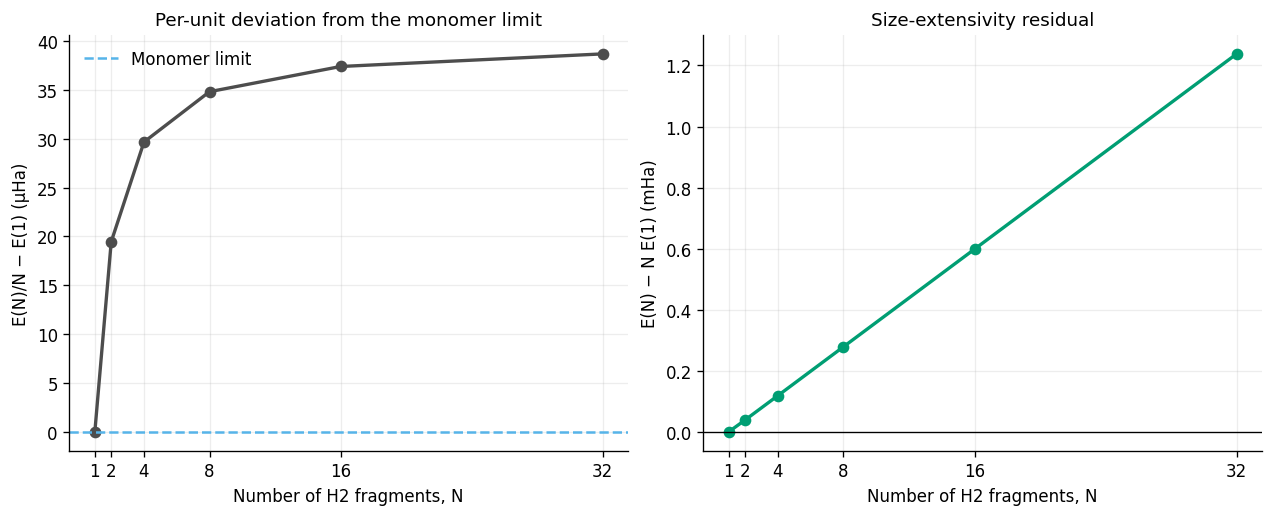

In [2]:
results_path = Path("data/results/02_size_extensivity/production_sweep.json")
size_data = json.loads(results_path.read_text())
rows = size_data["extensivity"] + [size_data["n32_parent_only"]]
rows = sorted(rows, key=lambda r: r["n"])
n = np.array([r["n"] for r in rows])
energies = np.array([r["parent_e_tot"] for r in rows])
e1 = energies[n == 1][0]
residual_mha = 1000 * (energies - n * e1)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)
per_unit_shift_uha = 1e6 * (energies / n - e1)
axes[0].plot(n, per_unit_shift_uha, "o-", color=COLORS["parent"], linewidth=2)
axes[0].axhline(0, color=COLORS["adapter"], linestyle="--", label="Monomer limit")
axes[0].set(xlabel="Number of H2 fragments, N", ylabel="E(N)/N − E(1) (μHa)",
            title="Per-unit deviation from the monomer limit")
axes[0].set_xticks(n)
axes[0].legend()

axes[1].plot(n, residual_mha, "o-", color=COLORS["generalized"], linewidth=2)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Number of H2 fragments, N", ylabel="E(N) − N E(1) (mHa)",
            title="Size-extensivity residual")
axes[1].set_xticks(n)
plt.show()

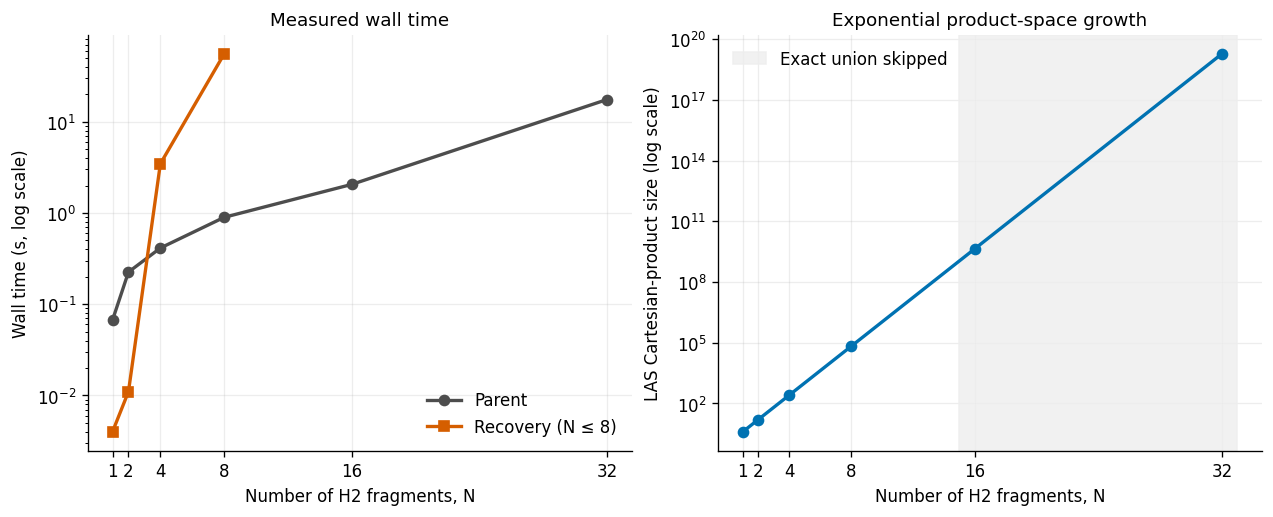

In [3]:
parent_wall = np.array([r["wall_s_parent"] for r in rows])
product_size = np.array([r["product_size"] for r in rows], dtype=float)
recovery_rows = [r for r in rows if r["recovery_attempted"]]
nr = np.array([r["n"] for r in recovery_rows])
recovery_wall = np.array([r["wall_s_recovery"] for r in recovery_rows])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)
axes[0].plot(n, parent_wall, "o-", label="Parent", color=COLORS["parent"], linewidth=2)
axes[0].plot(nr, recovery_wall, "s-", label="Recovery (N ≤ 8)", color=COLORS["free"], linewidth=2)
axes[0].set_yscale("log")
axes[0].set(xlabel="Number of H2 fragments, N", ylabel="Wall time (s, log scale)",
            title="Measured wall time")
axes[0].set_xticks(n)
axes[0].legend()

axes[1].plot(n, product_size, "o-", color=COLORS["union"], linewidth=2)
axes[1].axvspan(15, 33, color="#EEEEEE", alpha=0.8, label="Exact union skipped")
axes[1].set_yscale("log")
axes[1].set(xlabel="Number of H2 fragments, N", ylabel="LAS Cartesian-product size (log scale)",
            title="Exponential product-space growth")
axes[1].set_xticks(n)
axes[1].legend()
plt.show()

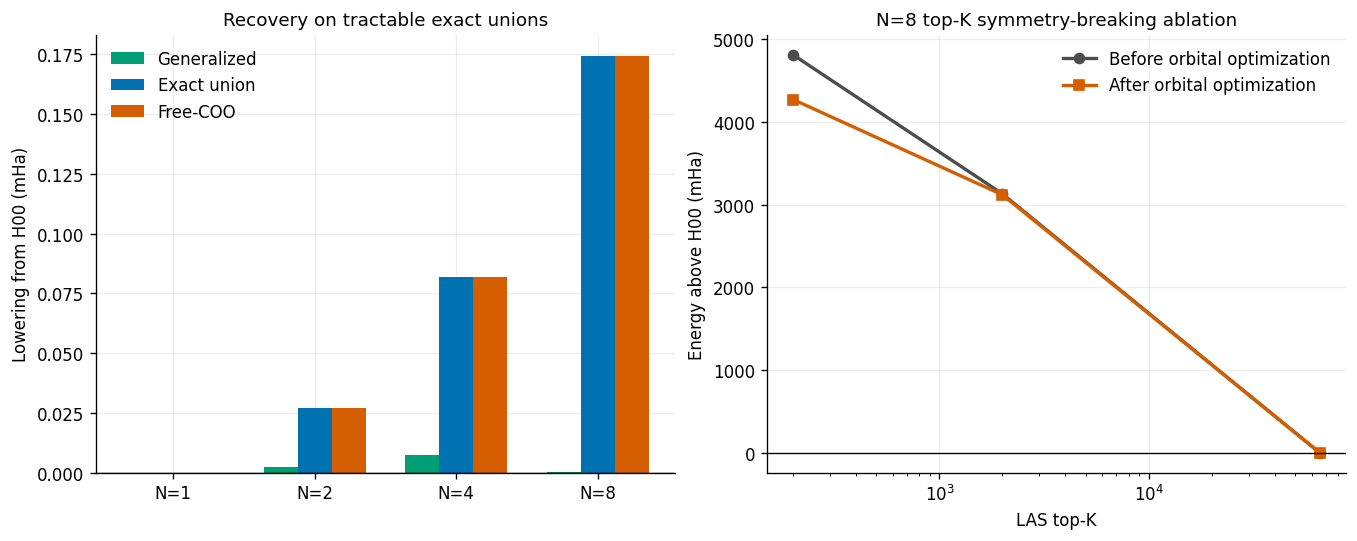

In [4]:
methods = {
    "Generalized": ("generalized", COLORS["generalized"]),
    "Exact union": ("union", COLORS["union"]),
    "Free-COO": ("free_coo", COLORS["free"]),
}
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4), constrained_layout=True)
x = np.arange(len(recovery_rows)); width = 0.24
for j, (label, (field, color)) in enumerate(methods.items()):
    vals = [1000 * (r["h00"] - r[field]) for r in recovery_rows]
    axes[0].bar(x + (j-1)*width, vals, width, label=label, color=color)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xticks(x, [f"N={r['n']}" for r in recovery_rows])
axes[0].set_ylabel("Lowering from H00 (mHa)")
axes[0].set_title("Recovery on tractable exact unions")
axes[0].legend()

ablation = size_data["ablation_topk_n8"]
k = np.array([r["las_top_k"] for r in ablation])
before = np.array([r["e_before_minus_h00_mha"] for r in ablation])
after = before + np.array([r["e_after_minus_e_before_mha"] for r in ablation])
axes[1].plot(k, before, "o-", label="Before orbital optimization", color=COLORS["parent"], linewidth=2)
axes[1].plot(k, after, "s-", label="After orbital optimization", color=COLORS["free"], linewidth=2)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xscale("log")
axes[1].set(xlabel="LAS top-K", ylabel="Energy above H00 (mHa)",
            title="N=8 top-K symmetry-breaking ablation")
axes[1].legend()
plt.show()